<h2 align = 'center'> Brazilian E-Commerce Public Dataset by Olist </h2>
<div align="center"> 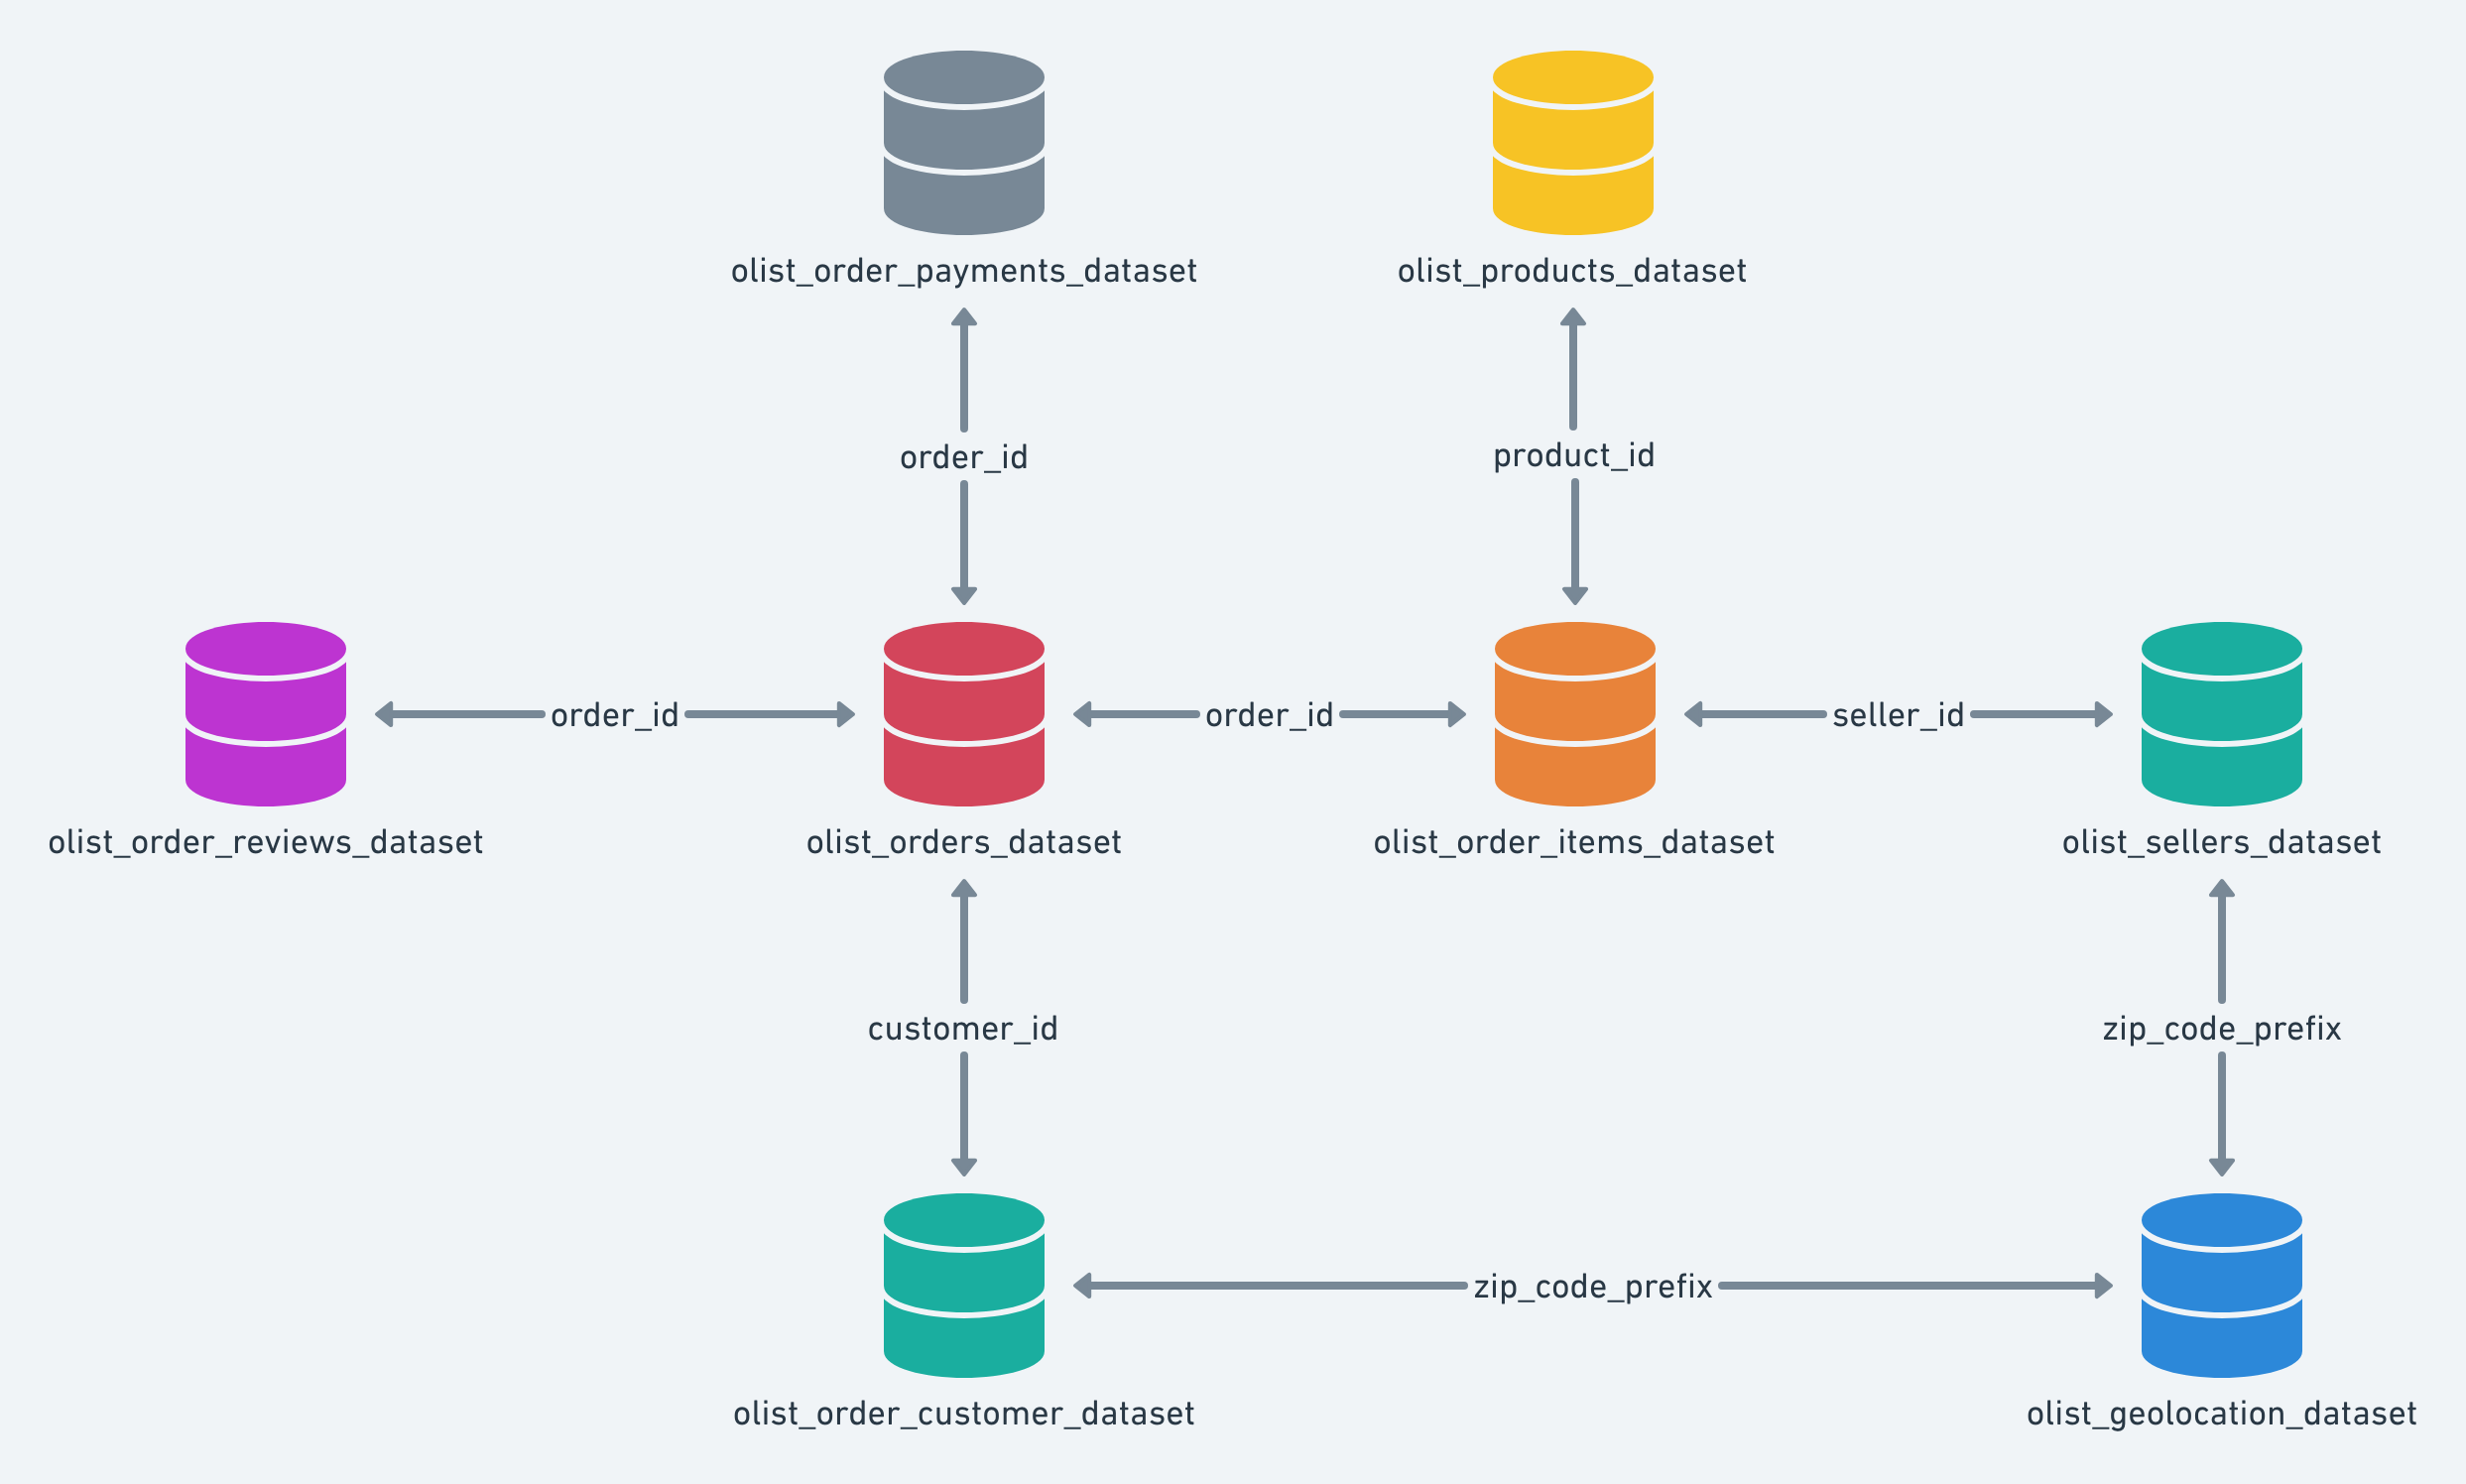 </div>


<div align="center"> <img src="https://storage.googleapis.com/kaggle-datasets-images/55151/105464/d59245a7014a35a35cc7f7b721de4dae/dataset-cover.png?t=2018-09-21-16-21-21" alt="Centered image"> </div>

Добро пожаловать! Это общедоступный бразильский набор данных о заказах, сделанных в интернет-магазине Olist. В наборе данных содержится информация о 100 000 заказов, сделанных с 2016 по 2018 год на различных торговых площадках Бразилии. С его помощью можно просмотреть заказ в разных аспектах: от статуса заказа, цены, оплаты и доставки до местоположения покупателя, характеристик товара и, наконец, отзывов покупателей. Мы также опубликовали набор данных с геолокацией, в котором бразильские почтовые индексы сопоставлены с координатами широты и долготы.

In [1]:
#Библиотеки для EDA
import duckdb
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from cycler import cycler

#ML
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    KFold,
    RandomizedSearchCV,
    GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

#Metrics
from sklearn.metrics import (
    roc_auc_score, 
    average_precision_score,
    recall_score
)

Импортирование библиотек

In [2]:
warnings.filterwarnings('ignore')

#colors
colormap = sns.diverging_palette(220, 10, as_cmap = True)
colorbox = [
    "#fb4934",  # Красный
    "#fabd2f",  # Желтый
    "#b8bb26",  # Зеленый
    "#83a598",  # Голубой
    "#d3869b",  # Фиолетовый
    "#fe8019",  # Ораньжевый
    "#8ec07c",  # Бирюзовый
]

rc = {
    "axes.facecolor": "#282828",
    "figure.facecolor": "#282828",
    "axes.edgecolor": "#3c3836",
    "grid.color": "#504945",
    "axes.labelcolor": "#ebdbb2",
    "xtick.color": "#d5c4a1",
    "ytick.color": "#d5c4a1",
    "grid.alpha": 0.3,
    "axes.prop_cycle": cycler(color=colorbox),
    "legend.facecolor": "#DCDCDC",
    "text.color": "ebdbb2", 
    "axes.titlecolor": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "legend.labelcolor": "white",
    "legend.title_fontsize": 12,
}

sns.set(rc=rc, style="darkgrid")
# Устанавливаем настройку rc и стиль "darkgrid" seaborn


palette_sex={"female" : "#c90076", "male": "#2986CC"}
palette_surv = {0: "#00ffff", 1: "#ff0000"}

Константы

In [3]:
#Функция для визуализации EDA графиков: гистограмма, boxplot
def num_plot(data,column_list,bins=50,figsize=(6,3)):
    for column in column_list:
        plt.figure(figsize=(figsize))
        # Первый subplot - ГИСТОГРАММА
        plt.subplot(1,2,1)
        sns.histplot(data=data,x=column,kde=True,bins=bins, palette=colorbox, alpha=0.7)
        plt.title(f'Гистограмма частоты {column} относительно целевой переменной',color='white')
        plt.xlabel(f'Значения {column}',color='white')
        plt.ylabel('Частота',color='white')
        plt.grid()
        # Второй subplot - BOXPLOT
        plt.subplot(1,2,2)
        sns.boxplot(data=data,y=column, palette=colorbox)
        plt.title(f'Boxplot {column}',color='white')
        plt.xlabel('Boxplot',color='white')
        plt.ylabel('Значения',color='white')
        plt.grid()
        plt.show()

#Функция визуализации pie charm
def pie_charm(values,index,title='',colors=[colorbox[0],colorbox[1]]):
    plt.figure(figsize=(14, 7))
    plt.pie(
        values,
        labels=index,
        startangle=90, frame=True, radius=1.3,
        wedgeprops={'linewidth': 1, 'edgecolor': 'white'},
        textprops={'fontsize': 12, 'weight': 'bold'},
        autopct='%1.1f%%',
        colors=colors,
    )
    plt.legend()
    plt.title(title,color='white')
    plt.show()

#Функция для визуализации EDA графиков: countplot
def count_plot(data,column_list,figsize=(9,3),palette=colorbox, rotation=90):
    for column in column_list:
        plt.figure(figsize=figsize)
        sns.countplot(data=data,x=column,palette=colorbox)
        plt.title(f'Количество {column}',color='white')
        plt.xlabel('Значения',color='white')
        plt.ylabel('Количество значений',color='white')
        plt.xticks(fontsize=7,rotation=rotation)
        plt.show()

#Функция визуализации линейной зависимости
def plotlm(x_var, y_var, row_var=None):
    lm = sns.lmplot(
        data=df_train,
        x=x_var,
        y=y_var,
        row=row_var,
        hue = row_var,
        lowess=True,
        height=2,
        aspect=4,
        palette=palette_sex ,
        col="survived",
        line_kws={"color": "#23272a"},
        scatter_kws={"alpha": 0.3},
    )
    for ax in lm.axes.flatten():
        ax.tick_params(color='white')
        ax.xaxis.label.set_color("white")
        ax.yaxis.label.set_color("white")

        lm.set_titles(
            col_template="Target value:{col_name}",
            color="white",
            size=12,
            weight="bold"
    )

    plt.suptitle(
        f"{x_var.replace('_', ' ').title()} VS {y_var.replace('_', ' ').title()} by Target Variable",
        y=1.02,
        fontsize=16,color='white',
    )
    
    plt.show()

Функции

# Загрузка данных и первичный анализ

In [4]:
olist_customers = pd.read_csv('datasets/olist/olist_customers_dataset.csv')
olist_geo = pd.read_csv('datasets/olist/olist_geolocation_dataset.csv')
olist_order_items = pd.read_csv('datasets/olist/olist_order_items_dataset.csv')
olist_order_payments = pd.read_csv('datasets/olist/olist_order_payments_dataset.csv')
olist_order_reviews = pd.read_csv('datasets/olist/olist_order_reviews_dataset.csv')
olist_orders = pd.read_csv('datasets/olist/olist_orders_dataset.csv')
olist_products = pd.read_csv('datasets/olist/olist_products_dataset.csv')
olist_sellers = pd.read_csv('datasets/olist/olist_sellers_dataset.csv')
product_cat_name_translation = pd.read_csv('datasets/olist/product_category_name_translation.csv')

#### olist_customers

* customer_id - идентификатор, используемый для связи с заказами. Каждому заказу присваивается уникальный customer_id.
* customer_unique_id - уникальный идентификатор клиента. Поскольку один и тот же покупатель получает новый customer_id для каждого нового заказа, это поле позволяет отслеживать повторные покупки. Без него каждый заказ выглядел бы как сделанный новым клиентом.
* customer_zip_code_prefix - первые пять цифр почтового индекса.
* customer_city - город проживания клиента.
* customer_state - штат проживания клиента.

In [5]:
olist_customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [6]:
olist_customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [7]:
print(f"Наличие явных дубликатов в датасете 'olist_customers': {olist_customers.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_customers': {olist_customers[['customer_unique_id','customer_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_customers': 0
Наличие неявных дубликатов в датасете 'olist_customers': 0


Таблица olist_customers содержит информацию о клиентах. Пропуски и дубликаты отсутствуют, названия строк соответствуют их содержанию, типы данных определены корректно.

In [8]:
print('Количество городов клиентов',olist_customers['customer_city'].nunique())
print('Количество штатов клиентов',olist_customers['customer_state'].nunique())

Количество городов клиентов 4119
Количество штатов клиентов 27


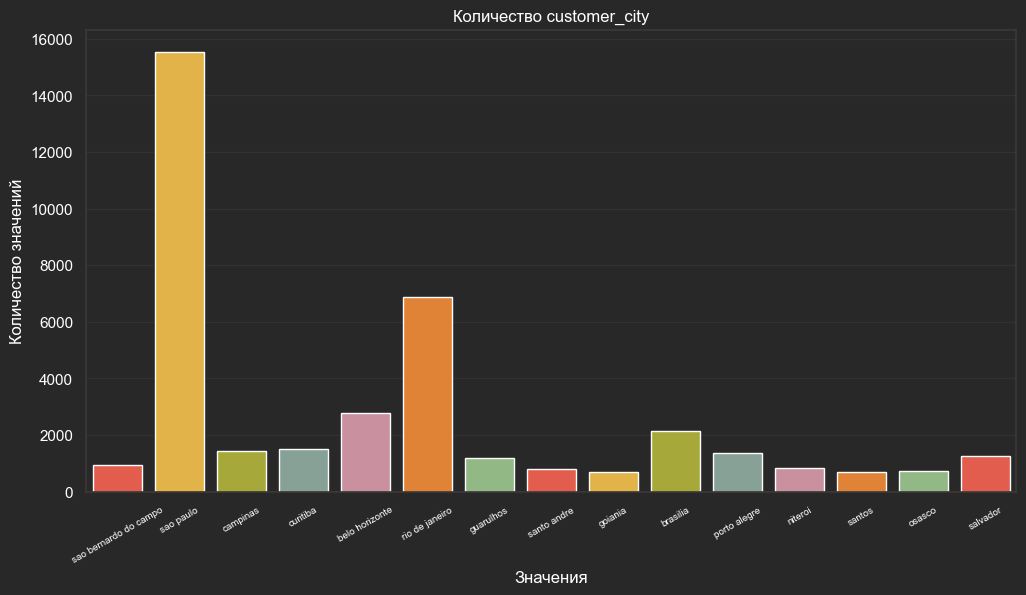

In [9]:
customer_city_names = olist_customers['customer_city'].value_counts().sort_values(ascending=False).index
customer_city_names = customer_city_names[:15]
the_most_frequent_cities = olist_customers.loc[olist_customers['customer_city'].isin(customer_city_names)]
count_plot(the_most_frequent_cities, ['customer_city'], figsize=(12,6), rotation=30)

Данные по городам показывают выраженную географическую концентрацию покупателей. Топ-15 городов возглавляет Сан-Паулу с большим отрывом - 15 540 заказов, что примерно в 2.3 раза больше, чем у следующего по популярности Рио-де-Жанейро (6 882). Остальные города уже существенно уступают: Белу-Оризонти (2 773), Бразилиа (2 131) и Куритиба (1 521)

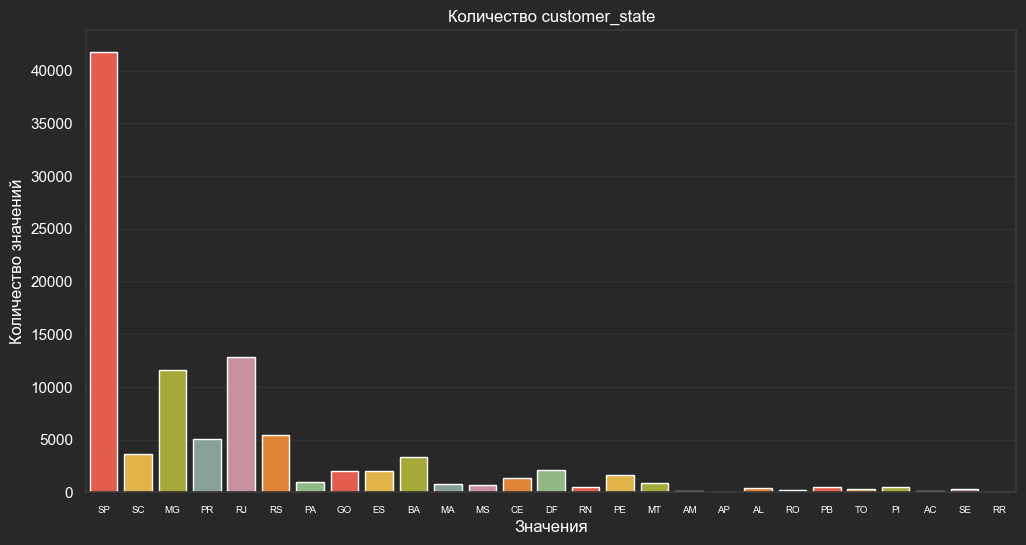

In [10]:
count_plot(olist_customers, ['customer_state'], figsize=(12,6), rotation=0)

На уровне штатов картина аналогичная: штат Сан-Паулу (SP) доминирует с 41 746 заказами - это почти треть всей выборки. За ним следуют Рио-де-Жанейро (RJ, 12 852) и Минас-Жерайс (MG, 11 635). Северные и северо-западные штаты (AM, AC, AP, RR) представлены крайне слабо (менее 200 заказов каждый), что отражает реальную экономическую диспропорцию регионов Бразилии. Для модели это означает потенциальный дисбаланс по географическому признаку, который стоит учесть при fe.

#### olist_geo

* geolocation_zip_code_prefix: первые 5 цифр почтового индекса.
* geolocation_lat: широта
* geolocation_lng: долгота
* geolocation_city: город
* geolocation_state штат

In [11]:
olist_geo.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [12]:
olist_geo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


#### olist_order_items

* order_id: уникальный идентификатор заказа.
* order_item_id: порядковый номер, определяющий количество товаров, включенных в один и тот же заказ.
* product_id: уникальный идентификатор продукта.
* seller_id: уникальный идентификатор продавца.
* shipping_limit_date: показывает дату отправки заказа продавцом логистическому партнеру.
* price: цена товара.
* freight_value: стоимость доставки товара

In [13]:
olist_order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [14]:
olist_order_items.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [15]:
print(f"Наличие явных дубликатов в датасете 'olist_order_items': {olist_order_items.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_order_items': {olist_order_items[['order_id','seller_id','product_id','order_item_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_order_items': 0
Наличие неявных дубликатов в датасете 'olist_order_items': 0


Таблица olist_order_items содержит информацию о предметах заказа. Пропуски и дубликаты отсутствуют, названия строк соответствуют их содержанию, типы данных определены корректно.

In [16]:
olist_order_items['shipping_limit_date'] = pd.to_datetime(
    olist_order_items['shipping_limit_date'],
    format='%Y-%m-%d %H:%M:%S'
)

Тип данных даты и времени был преобразован в верный

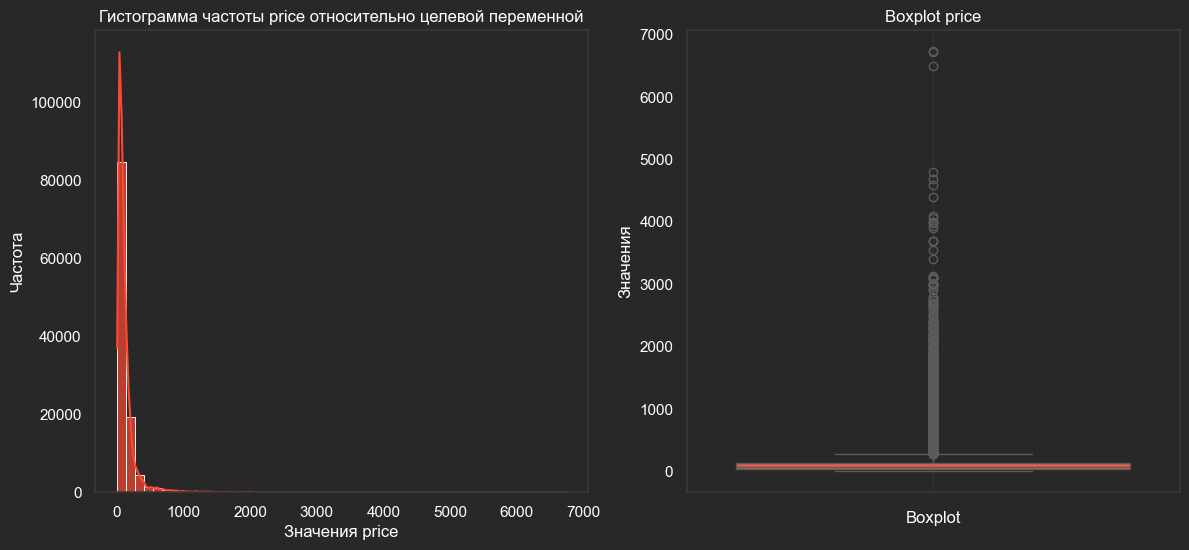

In [17]:
num_plot(olist_order_items,['price'], figsize=(14,6))

In [18]:
olist_order_items['price'].describe()


count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

Распределение price сильно правосторонне скошено, дорогостоящие товары существенно смещают среднее. Основная масса заказов сосредоточена в диапазоне до 300 единиц, при этом медиана составляет всего 74.99, тогда как среднее - 120.65, что говорит о значительном влиянии выбросов на правом хвосте. Максимальное значение - 6 735, что в ~50 раз превышает медиану. IQR составляет 95 (от 39.90 до 134.90) - 50% заказов укладываются в относительно узкий диапазон недорогих товаров.
Стандартное отклонение 183.63 при среднем 120.65 говорит о крайне высокой дисперсии.

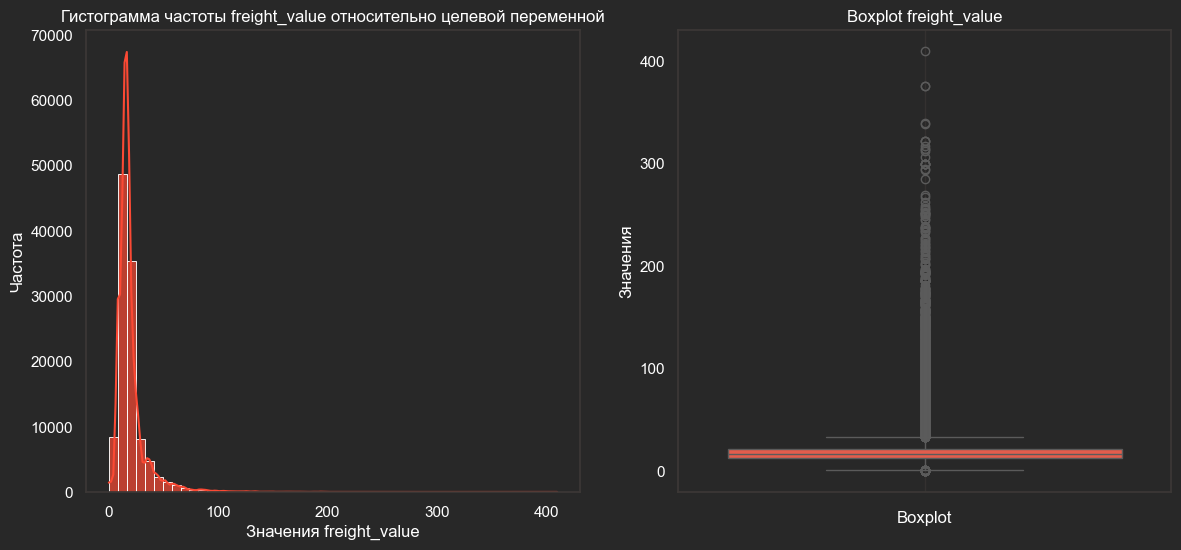

In [19]:
num_plot(olist_order_items,['freight_value'], figsize=(14,6))

In [20]:
olist_order_items['freight_value'].describe()


count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

freight_value демонстрирует схожую картину правостороннего скоса, но менее экстремальную. Медиана равна 16.26, среднее - 19.99, IQR от 13.08 до 21.15. Максимум - 409.68, минимум - 0 (бесплатная доставка). Стандартное отклонение 15.81 умеренное относительно среднего, но выбросы присутствуют - боксплот показывает ряд значений в диапазоне от ~200 до ~410, которые, вероятно, соответствуют дорогостоящей доставке в отдалённые регионы

#### olist_order_payments

* order_id: уникальный идентификатор заказа.
* payment_sequential: клиент может оплатить заказ несколькими способами оплаты. Если он это сделает, будет создана последовательность.
* payment_type: способ оплаты, выбранный клиентом.
* payment_installments: количество платежей, выбранных клиентом.
* payment_value: стоимость транзакции.

In [21]:
olist_order_payments.head()


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [22]:
olist_order_payments.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [23]:
print(f"Наличие явных дубликатов в датасете 'olist_order_payments': {olist_order_payments.duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_order_payments': 0


Таблица olist_order_payments содержит информацию о оплате заказов. Пропуски и дубликаты отсутствуют, названия строк соответствуют их содержанию, типы данных определены корректно.

In [24]:
print(f'Уникальные значения признака "payment_sequential":{olist_order_payments.payment_sequential.unique()}')

Уникальные значения признака "payment_sequential":[ 1  2  4  5  3  8  6  7 10 11 17 19 27 12  9 15 13 14 16 25 22 26 29 28
 18 21 24 23 20]


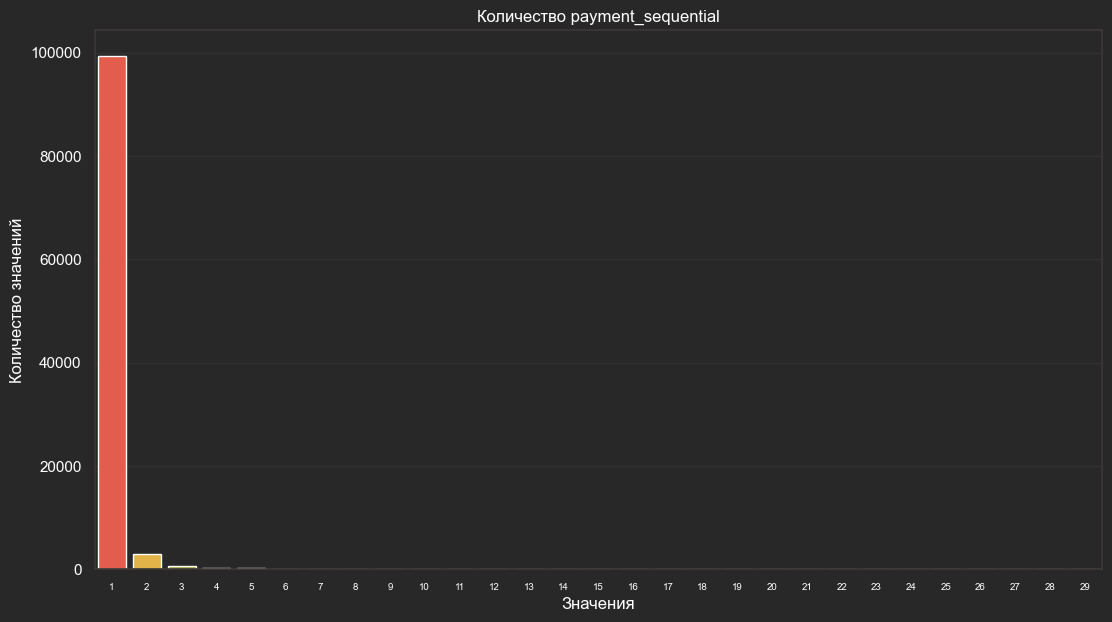

In [25]:
count_plot(olist_order_payments, ['payment_sequential'], figsize=(13,7), rotation=0)

Подавляющее большинство заказов оплачивается за один платёж - 99 360 из ~103 400, то есть около 96%. Два платежа используются уже в 3 039 случаях, а далее частота резко падает. Значения от 10 и выше единичны и могут представлять рассрочку на длительный срок. Признак сильно несбалансирован и в большинстве случаев будет нести мало информации. Возможно стоит трансформировать его в бинарный 1 платёж / более 1 платежа

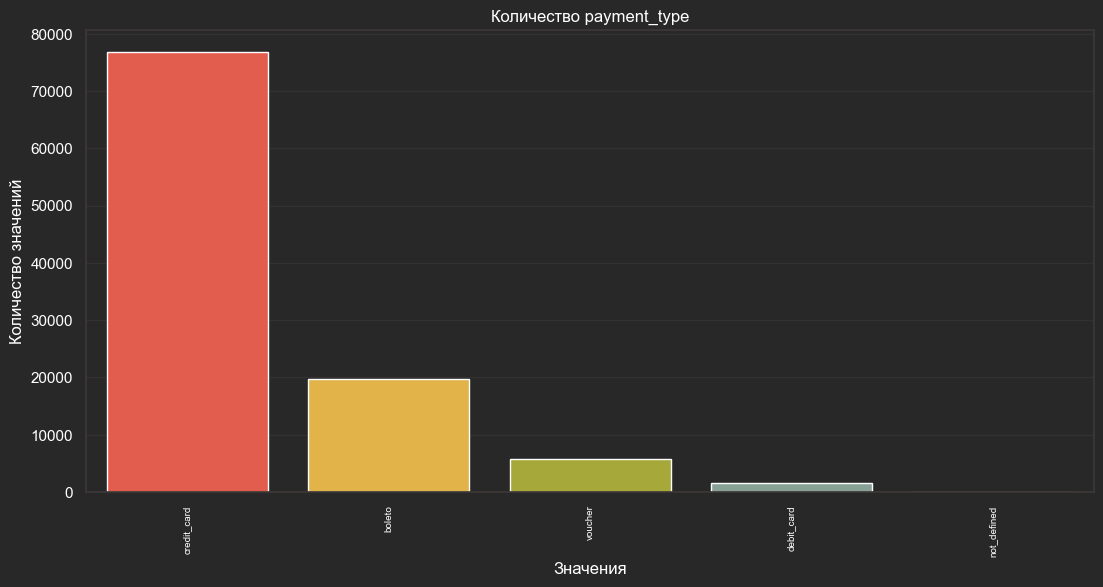

In [26]:
count_plot(olist_order_payments,['payment_type'],figsize=(13,6))

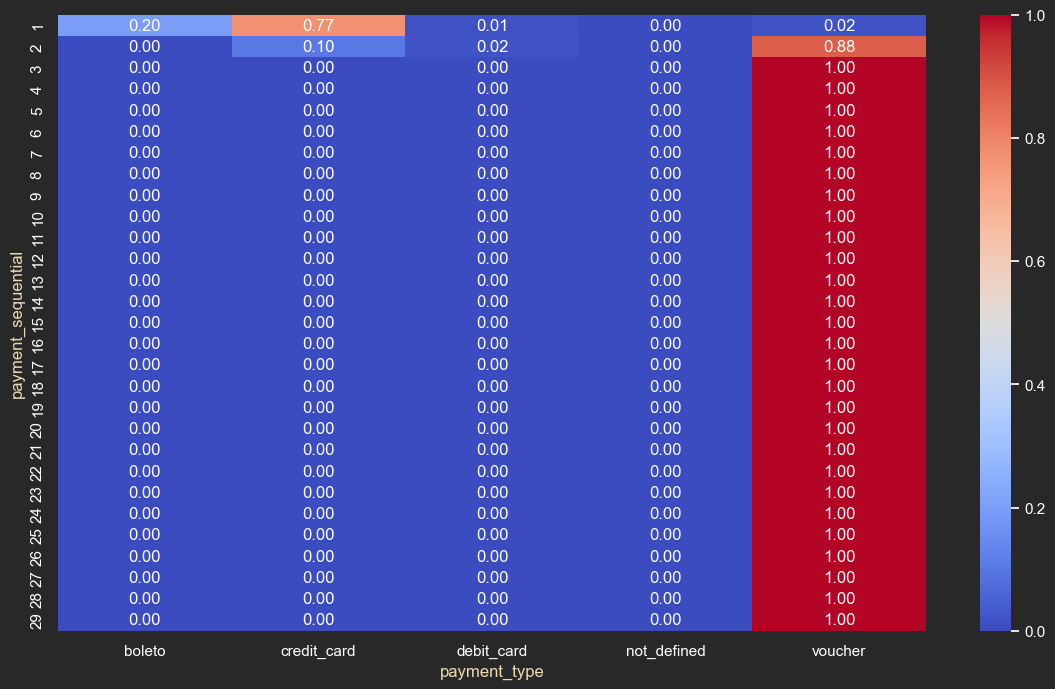

In [27]:
plt.figure(figsize=(14,8))
sns.heatmap(
    pd.crosstab(olist_order_payments['payment_sequential'], olist_order_payments['payment_type'], normalize='index'),
    annot = True,
    cmap = 'coolwarm',
    cbar = True,
    fmt = '.2f'
)
plt.grid()
plt.show()

Тепловая карта соотношения payment_sequential и payment_type выявляет чёткую закономерность: при одном платеже используются все типы оплаты (boleto - 20%, credit_card - 77%, debit_card - 1%, voucher - 2%). Начиная со второго платежа и далее используется только voucher (0.88 и выше, с третьего по двадцать девятый - 1.00)

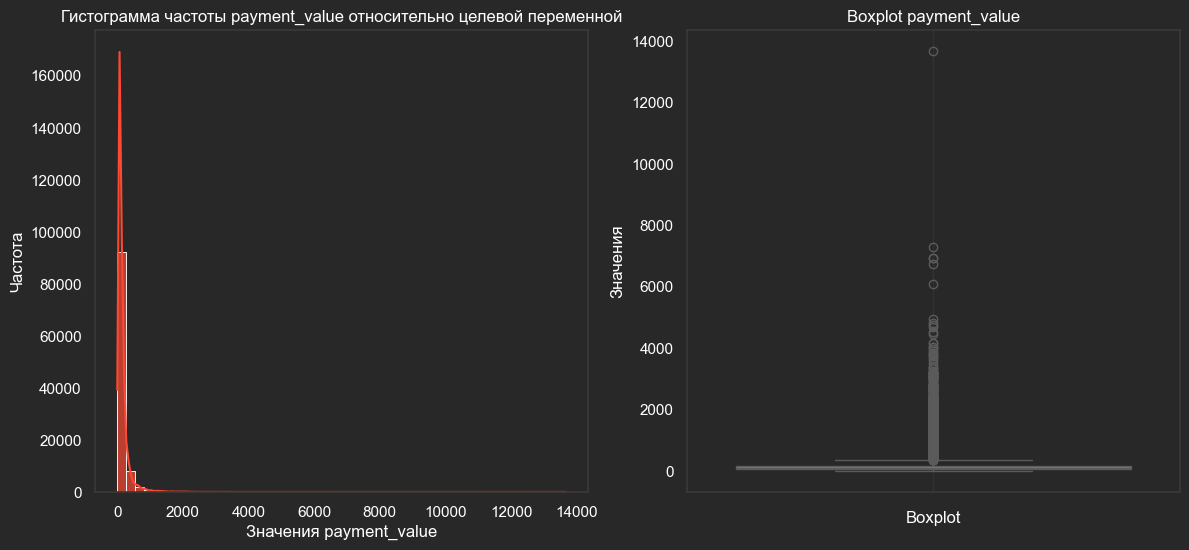

In [28]:
num_plot(olist_order_payments,['payment_value'],figsize=(14,6))

In [29]:
olist_order_payments['payment_value'].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

#### olist_order_reviews

* review_id: уникальный идентификатор отзыва.
* order_id: уникальный идентификатор заказа.
* review_score: оценка заказа.
* review_comment_title: заголовок комментария.
* review_comment_message: комментарий к отзыву.
* review_creation_date: дата отзыва.
* review_answer_timestamp: дата ответа на отзыв.

In [30]:
olist_order_reviews.head()


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [31]:
olist_order_reviews.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [32]:
print(f"Наличие явных дубликатов в датасете 'olist_order_reviews': {olist_order_reviews.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_order_reviews': {olist_order_reviews[['review_id','order_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_order_reviews': 0
Наличие неявных дубликатов в датасете 'olist_order_reviews': 0


Таблица olist_order_reviews содержит информацию о отзывах на заказы. В данных содержатся пропуски в признаках текста отзывов, а также в заголовках отзывов. Можно предположить, что люди решили не писать комментарий к отзыву, а лишь оставить оценку заказу. Эта информация не подлежит восстановлению истинных значений, отсутствует более 50% значений, поэтому я решил заполнить пропуски костантным значением, чтобы не терять оценки заказов.

In [33]:
olist_order_reviews.fillna('NaN',inplace=True)

olist_order_reviews['review_creation_date'] = pd.to_datetime(
    olist_order_reviews['review_creation_date']
)
olist_order_reviews['review_answer_timestamp'] = pd.to_datetime(
    olist_order_reviews['review_answer_timestamp']
)

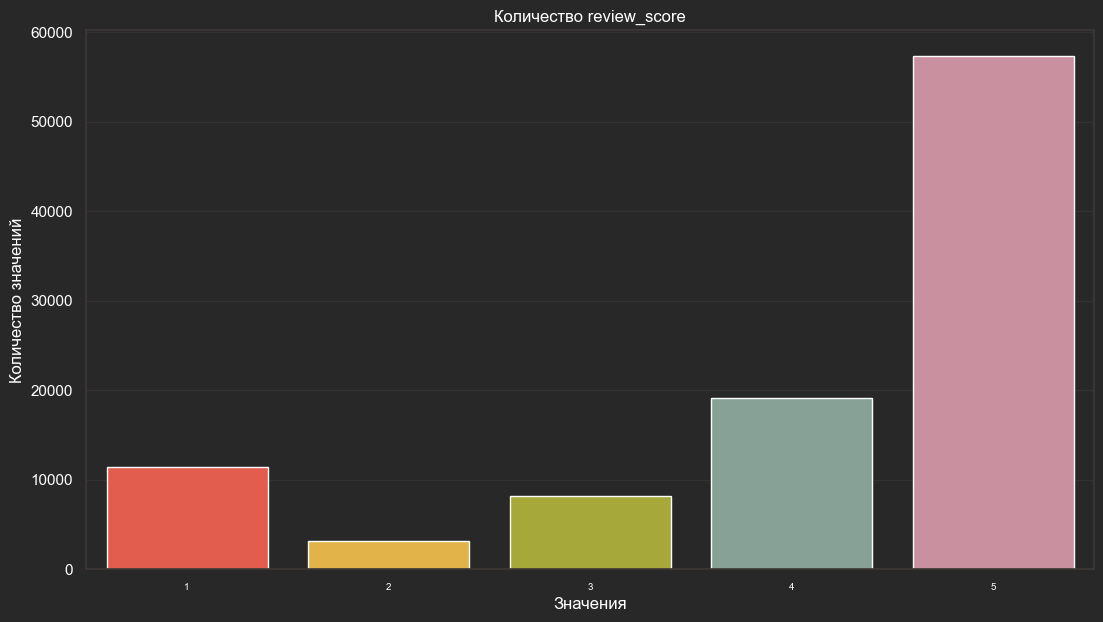

In [34]:
count_plot(olist_order_reviews,['review_score'], figsize=(13,7), rotation=0)

Распределение оценок явно несбалансированное и скошено в сторону положительных. Оценка 5 встречается чаще всего - 57 328 раз (~57% выборки). Оценка 4 - 19 142. При этом оценка 1 (11 424) занимает третье место и встречается заметно чаще, чем 3 (8 179) и 2 (3 151). Можно предположить, что люди зачастую ставят оценки только когда они очень довольны покупкой или когда разочарованы.

#### olist_orders

* order_id: уникальный идентификатор заказа.
* customer_id: ключ к набору данных о клиентах.
* order_status: ссылка на статус заказа.
* order_purchase_timestamp: показывает отметку времени покупки.
* order_approved_at: показывает отметку времени утверждения платежа.
* order_delivered_carrier_date: показывает отметку времени отправки заказа.
* order_delivered_customer_date: показывает фактическую дату доставки заказа клиенту.
* order_estimated_delivery_date: показывает предполагаемую дату доставки.

In [35]:
olist_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [36]:
olist_orders.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [37]:
print(f"Наличие явных дубликатов в датасете 'olist_orders': {olist_orders.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_orders': {olist_orders[['customer_id','order_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_orders': 0
Наличие неявных дубликатов в датасете 'olist_orders': 0


Таблица olist_orders содержит информацию о заказе. Есть наличие пропусков и неверно определенных типов данных. Содержание пропусков локализируется в признаках с датами (3% даных), которые не подлежат восстановлению, эти строки можно удалить.

In [38]:
olist_orders['order_approved_at'].fillna(
    olist_orders['order_approved_at'].mode().iloc[0], inplace=True
)
olist_orders['order_delivered_carrier_date'].fillna(
    olist_orders['order_delivered_carrier_date'].mode().iloc[0], inplace=True
)
olist_orders['order_delivered_customer_date'].fillna('NaN',inplace=True)

In [39]:
olist_orders.isna().sum()

order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

In [40]:
olist_orders['order_purchase_timestamp'] = pd.to_datetime(
    olist_orders['order_purchase_timestamp'],
    format='%Y-%m-%d %H:%M:%S'
)
olist_orders['order_approved_at'] = pd.to_datetime(
    olist_orders['order_approved_at'],
    format='%Y-%m-%d %H:%M:%S'
)
olist_orders['order_delivered_carrier_date'] = pd.to_datetime(
    olist_orders['order_delivered_carrier_date'],
    format='%Y-%m-%d %H:%M:%S'
)

olist_orders['order_estimated_delivery_date'] = pd.to_datetime(
    olist_orders['order_estimated_delivery_date'],
    format='%Y-%m-%d %H:%M:%S'
)

Признаки даты и времени были приведены к единому типу datetime

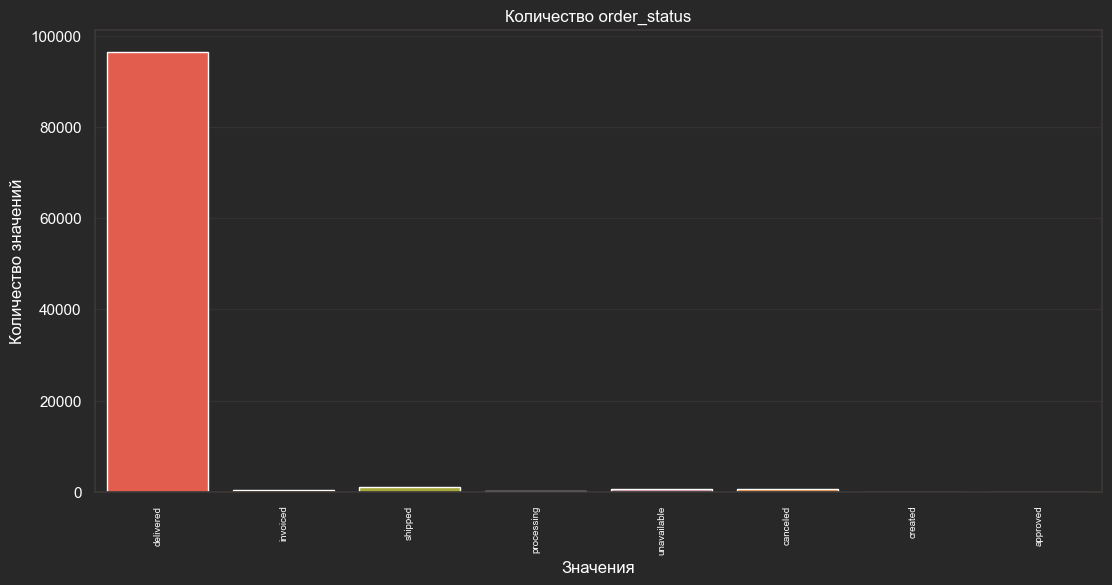

In [41]:
count_plot(olist_orders,['order_status'],figsize=(13,6))

In [42]:
olist_orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Большинство заказов были доставлены (96455) и лишь 6 заказов были отменены.

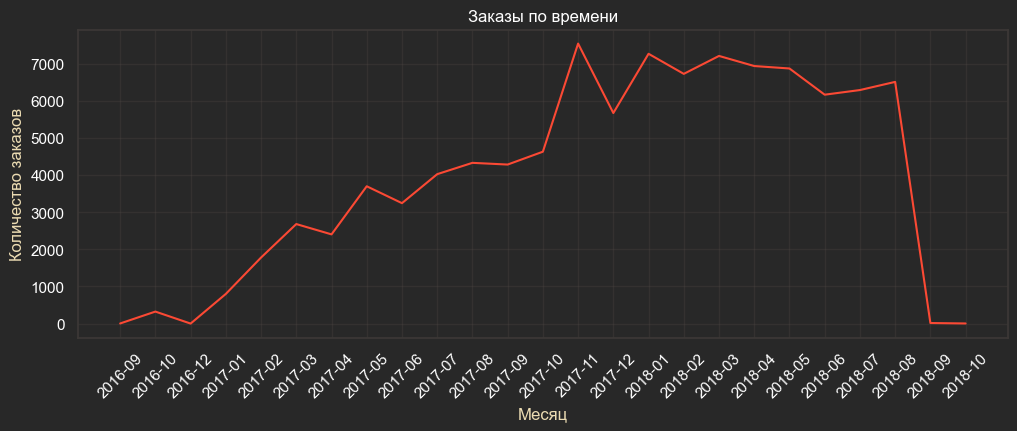

In [43]:
monthly_counts_orders = olist_orders['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()

plt.figure(figsize=(12,4))
sns.lineplot(
    x=monthly_counts_orders.index.astype(str),
    y=monthly_counts_orders.values,
)
plt.xticks(rotation=45)
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.title('Заказы по времени')
plt.show()

Наибольшее количество отзывов приходится на период с 2017-11 по 2018-08 (от 5500 до ~ 7000 отзывов в месяц). С 2016-10 по 2017-01 было минимальное количество отзывов (<200 в месяц). Вероятно, 2018 год вышел пиком продаж, а в 2016 бизнес только развивался. 2017-11 - месяцем с наибольшим объемом заказов (~ 7300)

#### olist_products

* product_id: уникальный идентификатор продукта.
* product_category_head: категория продукта.
* product_name_length: количество символов из названия продукта.
* product_description_length: количество символов из описания продукта.
* product_photos_qty: количество фотографий продукта.
* product_weight_g: вес продукта в граммах.
* product_length_cm: длина изделия ив сантиметрах.
* product height_cm: высота изделия в саинтиметрах.
* product_width_cm: ширина изделия в сантиметрах.

In [44]:
olist_products.head()


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [45]:
olist_products.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [46]:
print(f"Наличие явных дубликатов в датасете 'olist_products': {olist_products.duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_products': 0


In [47]:
olist_products.isna().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Количество пропусков немного относительно выборки, можно удалить их при этом не потеряв много важной информации.

In [48]:
olist_products.dropna(inplace=True)

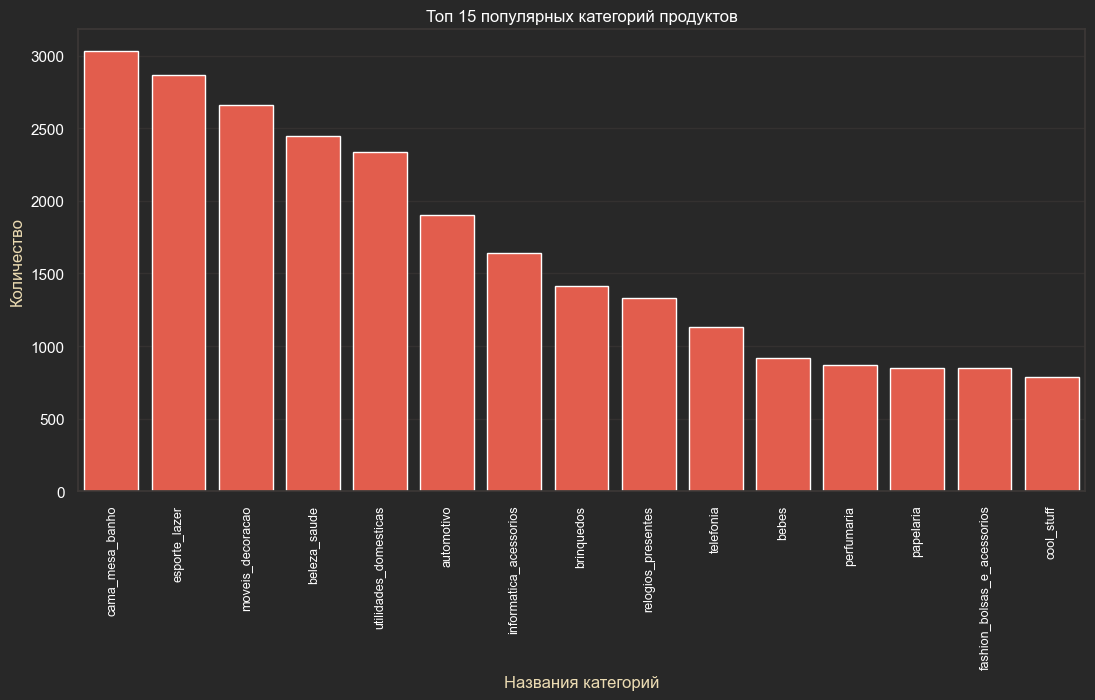

In [49]:
plt.figure(figsize=(13,6))
sns.barplot(olist_products['product_category_name'].value_counts().sort_values(ascending=False).head(15))
plt.title('Топ 15 популярных категорий продуктов')
plt.ylabel('Количество')
plt.xlabel('Названия категорий')
plt.xticks(fontsize=9, rotation=90)
plt.show()

In [50]:
print('Топ 10 популярных категорий товаров: \n \n', olist_products['product_category_name'].value_counts()[:10])

Топ 10 популярных категорий товаров: 
 
 product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64


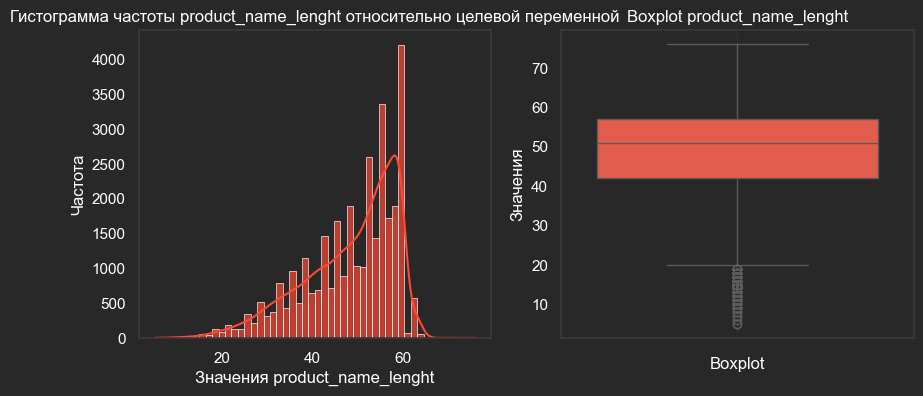

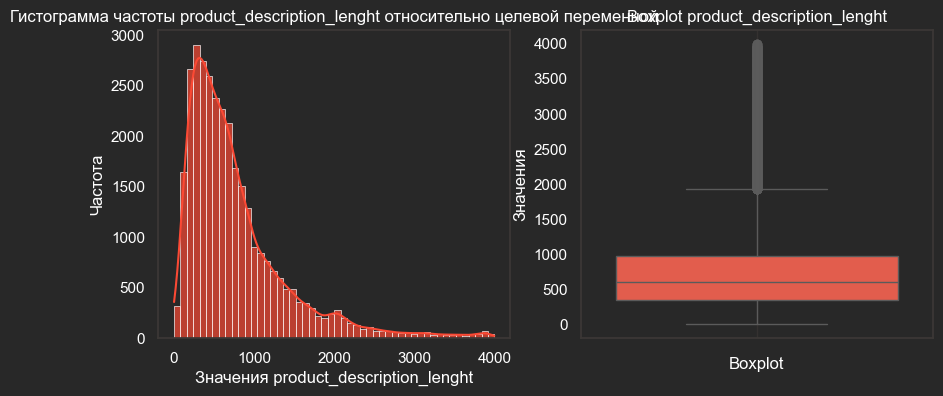

In [51]:
num_plot(olist_products, ['product_name_lenght', 'product_description_lenght'], figsize=(10,4))

In [52]:
print(olist_products['product_name_lenght'].describe(), '\n')
olist_products['product_name_lenght'].describe()

count    32340.000000
mean        48.476592
std         10.245699
min          5.000000
25%         42.000000
50%         51.000000
75%         57.000000
max         76.000000
Name: product_name_lenght, dtype: float64 



count    32340.000000
mean        48.476592
std         10.245699
min          5.000000
25%         42.000000
50%         51.000000
75%         57.000000
max         76.000000
Name: product_name_lenght, dtype: float64

**product_name_lenght и product_description_lenght**


* product_name_lenght: 

Распределение близко к нормальному - гистограмма симметрична с пиком около 55-60 символов, медиана (51) и среднее (48.5) близки, std умеренное (10.25). IQR от 42 до 57 - разброс небольшой. Боксплот показывает редкие выбросы снизу (минимум 5 символов). Признак не требует трансформаций перед масштабированием.

* product_description_lenght: 

Выраженный правый скос: пик гистограммы в диапазоне 200-500 символов, но среднее (771) заметно выше медианы (595) из-за длинного хвоста. IQR широкий - от 339 до 972. Максимум почти 4 000 символов.

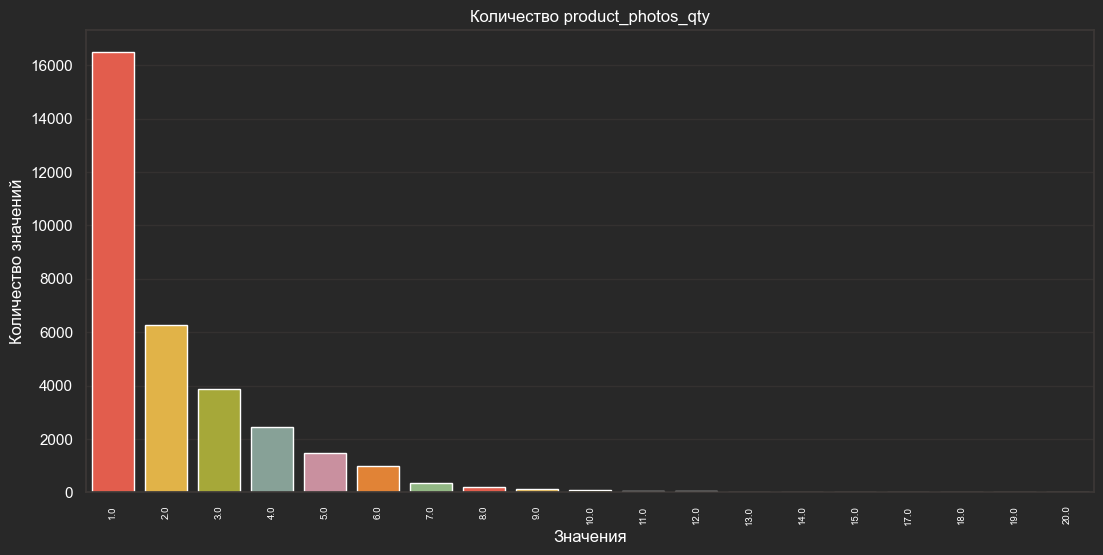

In [53]:
count_plot(olist_products, ['product_photos_qty'], figsize=(13,6))

Большинство продавцов прикладывают минимальное количество фото от 1 до 6. Больше 10 фотографий и до 20 встречаются очень редко

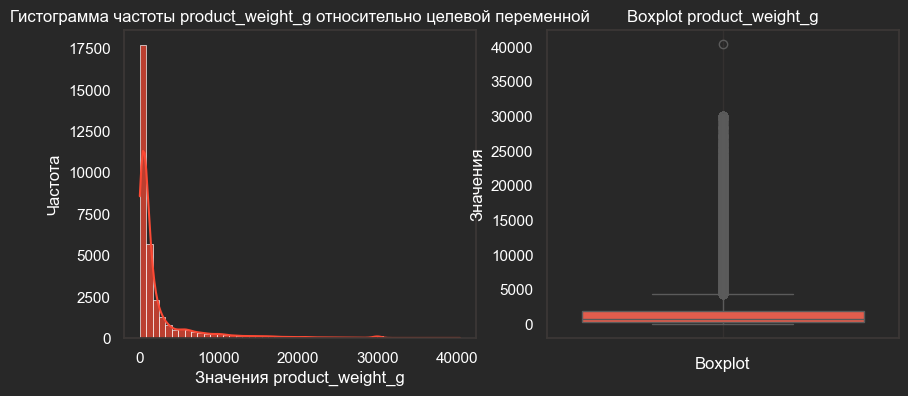

In [54]:
num_plot(olist_products, ['product_weight_g'], figsize=(10,4))

In [55]:
olist_products['product_weight_g'].describe()

count    32340.000000
mean      2276.956586
std       4279.291845
min          0.000000
25%        300.000000
50%        700.000000
75%       1900.000000
max      40425.000000
Name: product_weight_g, dtype: float64

Вес товара - один из самых скошенных признаков в датасете. Медиана - 700 г, среднее - 2 276 г, максимум - 40 425 г. Стандартное отклонение (4 282) почти вдвое превышает среднее (дисперсия экстремальная). IQR от 300 до 1 900 г показывает, что 50% товаров.

In [56]:
olist_products.loc[olist_products['product_weight_g'] > 40000]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
25166,26644690fde745fc4654719c3904e1db,cama_mesa_banho,59.0,534.0,1.0,40425.0,13.0,65.0,28.0


В признаке product_weight_g зафиксирована аномальная запись: товар категории cama_mesa_banho имеет вес 40 425 г при габаритах 13×65×28 см. Такое соотношение веса и размеров физически нереалистично

In [57]:
olist_products = olist_products.loc[olist_products['product_weight_g'] < 40000]

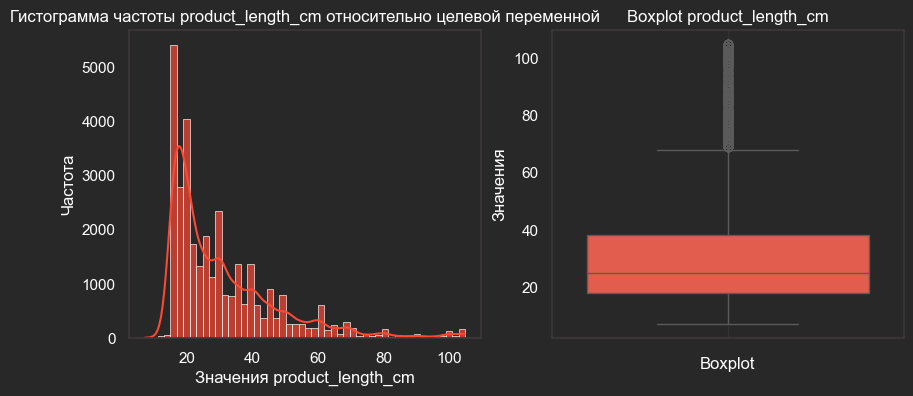

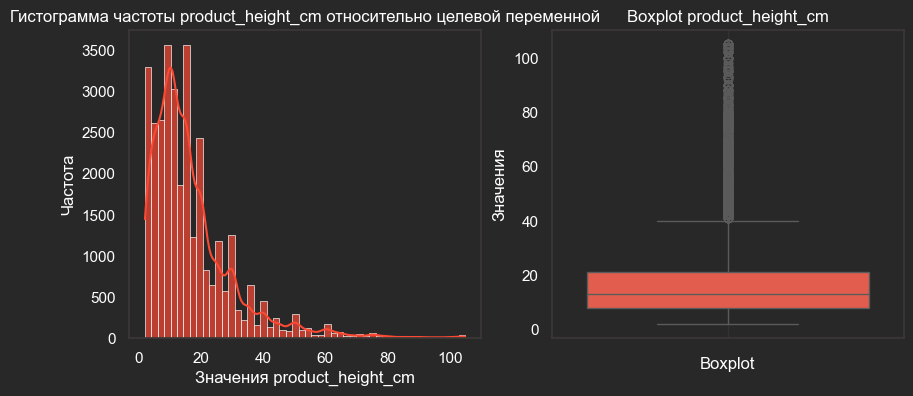

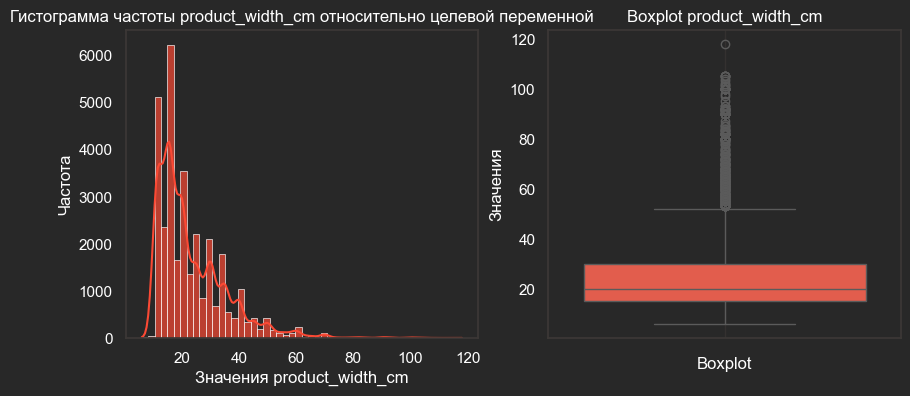

In [58]:
num_plot(olist_products, ['product_length_cm', 'product_height_cm', 'product_width_cm'], figsize=(10,4))

**product_length_cm, product_height_cm, product_width_cm**

Все три размерных признака демонстрируют схожую структуру - правосторонний скос с основной массой значений в нижнем диапазоне и длинным хвостом.

#### olist_sellers

* seller_id - уникальный идентификатор продавца.
* seller_zip_code_prefix - первые пять цифр почтового индекса.
* seller_city - город продавца.
* seller_state - штат продавца.

In [59]:
olist_sellers.head()


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [60]:
olist_sellers.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [61]:
print(f"Наличие явных дубликатов в датасете 'olist_sellers': {olist_sellers.duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_sellers': 0


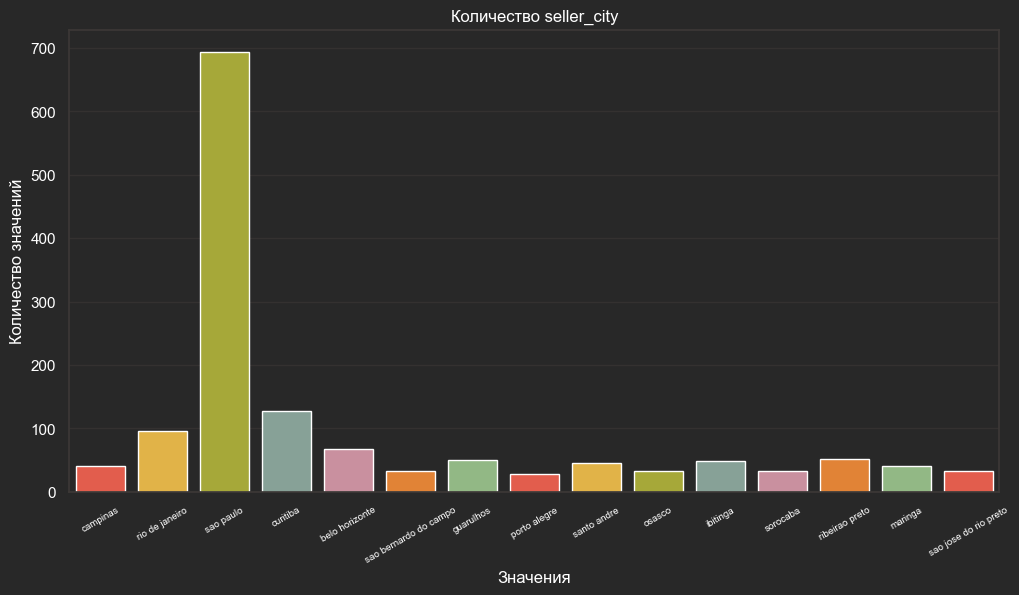

In [62]:
seller_city_names = olist_sellers['seller_city'].value_counts().sort_values(ascending=False).index
seller_city_names = seller_city_names[:15]
the_most_frequent_seller_cities = olist_sellers.loc[olist_sellers['seller_city'].isin(seller_city_names)]
count_plot(the_most_frequent_seller_cities, ['seller_city'], figsize=(12,6), rotation=30)

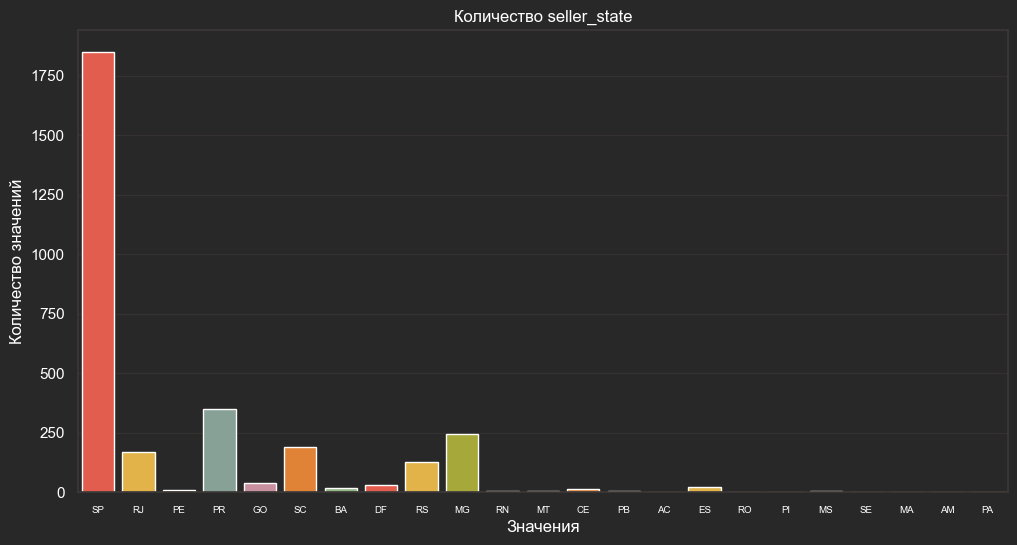

In [63]:
count_plot(olist_sellers, ['seller_state'], figsize=(12,6), rotation=0)

Продавцы сконцентрированы ещё сильнее, чем покупатели. Штат Сан-Паулу (SP) даёт 1 849 продавцов из ~3 095 (почти 60%). Следующие: Парана (PR, 349) и Минас-Жерайс (MG, 244). Многие штаты представлены единицами продавцов (AC, MA, AM, PA по 1). Среди городов лидирует Сан-Паулу (694), далее Куритиба (127) и Рио-де-Жанейро (96).

#### product_cat_name_translation

* product_category_name - название на родном языке
* product_category_name_english - перевод на английский

In [64]:
product_cat_name_translation.head()


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [65]:
product_cat_name_translation.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [66]:
print(f"Наличие явных дубликатов в датасете 'product_cat_name_translation': {product_cat_name_translation.duplicated().sum()}")

Наличие явных дубликатов в датасете 'product_cat_name_translation': 0


# Join таблиц

In [67]:
olist_geo_agg = olist_geo.groupby('geolocation_zip_code_prefix').agg(
    lat=('geolocation_lat', 'mean'),
    lng=('geolocation_lng', 'mean')
).reset_index()

In [68]:
df = pd.merge(olist_orders, olist_order_payments, on='order_id', how='inner')
df = df.merge(olist_order_reviews, on='order_id', how='inner')
df = df.merge(olist_customers, on='customer_id', how='inner')
df = df.merge(olist_order_items, on='order_id', how='inner')
df = df.merge(olist_products, on='product_id', how='inner')
df = df.merge(olist_sellers, on='seller_id', how='inner')
df = df.merge(product_cat_name_translation, on='product_category_name', how='left')
df = df.merge(
    olist_geo_agg.rename(columns={
        'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
        'lat': 'customer_lat', 'lng': 'customer_lng'
    }),
    on='customer_zip_code_prefix', how='left'
)

In [69]:
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_sequential,payment_type,...,product_weight_g,product_length_cm,product_height_cm,product_width_cm,seller_zip_code_prefix,seller_city,seller_state,product_category_name_english,customer_lat,customer_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,credit_card,...,500.0,19.0,8.0,13.0,9350,maua,SP,housewares,-23.576983,-46.587161
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,3,voucher,...,500.0,19.0,8.0,13.0,9350,maua,SP,housewares,-23.576983,-46.587161
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2,voucher,...,500.0,19.0,8.0,13.0,9350,maua,SP,housewares,-23.576983,-46.587161
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,boleto,...,400.0,19.0,13.0,19.0,31570,belo horizonte,SP,perfumery,-12.177924,-44.660711
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,credit_card,...,420.0,24.0,19.0,21.0,14840,guariba,SP,auto,-16.745150,-48.514783


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115630 entries, 0 to 115629
Data columns (total 42 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       115630 non-null  object        
 1   customer_id                    115630 non-null  object        
 2   order_status                   115630 non-null  object        
 3   order_purchase_timestamp       115630 non-null  datetime64[ns]
 4   order_approved_at              115630 non-null  datetime64[ns]
 5   order_delivered_carrier_date   115630 non-null  datetime64[ns]
 6   order_delivered_customer_date  115630 non-null  object        
 7   order_estimated_delivery_date  115630 non-null  datetime64[ns]
 8   payment_sequential             115630 non-null  int64         
 9   payment_type                   115630 non-null  object        
 10  payment_installments           115630 non-null  int64         
 11  

In [71]:
df.shape

(115630, 42)

In [72]:
df.duplicated().sum()

0

In [73]:
df.dropna(inplace=True)

#### same_state

In [74]:
df['same_state'] = (df['seller_state'] == df['customer_state']).astype(int)

df.groupby('same_state').agg(
    mean_freight=('freight_value', 'mean'),
    mean_review=('review_score', 'mean'),
    mean_price=('price', 'mean'),
    count=('price', 'count')
)

,mean_freight,mean_review,mean_price,count
same_state,,,,
0,23.771897,3.96974,129.938226,73562
1,13.491210,4.14830,104.115697,41733


Заказы вне штата дороже по доставке (23.7 > 13.5), дороже по товару (129 > 103) и получают более низкий review (4.02 < 4.20). Бинарный признак несет высокую важность для модели

#### freight_to_price_ratio

In [75]:
df['freight_to_price_ratio'] = df['freight_value'] / df['price']

geo_price = df.groupby('customer_state').agg(
    mean_price=('price', 'mean'),
    median_price=('price', 'median'),
    mean_freight=('freight_value', 'mean'),
    mean_freight_to_price_ratio=('freight_to_price_ratio', 'mean'),
    order_count=('price', 'count')
).sort_values('mean_freight', ascending=False)
geo_price

,mean_price,median_price,mean_freight,mean_freight_to_price_ratio,order_count
customer_state,,,,,
RR,151.669000,87.445,43.587000,0.603531,50
PB,189.069206,99.900,43.412885,0.520156,617
RO,166.666679,95.000,41.113249,0.594457,277
AC,182.715484,99.990,40.232473,0.496046,93
TO,167.138645,89.990,40.044548,0.509582,332
PI,161.347742,99.450,39.327097,0.502794,558
MA,144.819372,88.285,38.351014,0.545301,828
SE,152.528444,89.450,36.203546,0.471543,392
AL,178.772159,99.945,35.647907,0.474284,454


RR, PB, RO, AC, TO, PL, MA - freight_to_price_ratio от 0.49 до 0.59. То есть покупатель отдаёт от 50% до 60% от стоимости товара за доставку в дальние штаты. SP - 0.27, он же является главным офисом компании и самым популярным регионом по продажам. Это объясняет низкий спрос в дальних штатах с точки зрения экономии.

#### product_category_name agg

In [76]:
cat_profile = df.groupby('product_category_name').agg(
    mean_price=('price', 'mean'),
    median_price=('price', 'median'),
    mean_weight=('product_weight_g', 'mean'),
    max_weight=('product_weight_g', 'max'),
    mean_freight=('freight_value', 'mean'),
    count=('price', 'count')
).sort_values('mean_price', ascending=False)
print("Самые дорогие категории: \n")
display(cat_profile.head(15))
print("Самые дешевые категории: \n")
display(cat_profile.tail(15))

Самые дорогие категории: 



,mean_price,median_price,mean_weight,max_weight,mean_freight,count
product_category_name,,,,,,
pcs,1077.530602,1100.000,6977.777778,25950.0,47.310694,216
portateis_casa_forno_e_cafe,627.509103,617.995,5176.820513,16550.0,36.982821,78
eletrodomesticos_2,460.764644,229.900,9924.149813,30000.0,46.124419,267
agro_industria_e_comercio,332.706151,299.950,4248.309524,30000.0,27.646111,252
instrumentos_musicais,290.763136,94.900,3119.562588,30000.0,27.325668,711
eletroportateis,285.925980,99.990,3037.293276,30000.0,23.982189,699
telefonia_fixa,228.064515,67.440,563.182836,6050.0,17.551418,268
construcao_ferramentas_seguranca,211.861162,129.575,791.479798,9450.0,20.068182,198
relogios_presentes,201.953424,129.000,580.138690,22175.0,16.806022,6136


Самые дешевые категории: 



,mean_price,median_price,mean_weight,max_weight,mean_freight,count
product_category_name,,,,,,
fashion_esporte,72.224828,59.900,344.827586,1500.0,19.449310,29
fashion_underwear_e_moda_praia,71.890559,59.900,269.755245,2300.0,14.501469,143
telefonia,71.618689,29.990,262.027374,8100.0,15.723871,4676
livros_tecnicos,71.431004,57.490,1009.892193,8900.0,16.026245,269
fashion_roupa_infanto_juvenil,71.231250,69.945,265.000000,600.0,11.938750,8
bebidas,59.483906,47.490,1024.583333,9900.0,15.104896,384
alimentos,57.983740,49.000,659.155512,8238.0,14.322913,508
fashion_roupa_feminina,57.788800,49.495,553.000000,1700.0,12.928000,50
eletronicos,57.720099,21.900,798.905319,24050.0,16.784695,2820


При при средней цене доставки 43.7 у категории moveis_quarto, его средний вес составляет 10320 г, а средняя цена на продукты этой категории - 158. Доставка составляет ~28% цены товара. В то время как у категории pcs средний вес равен 6940 г, а средние цена доставки - 47.3 и цена товара - 1078 (Соотношение цены доставки и товара приемлемое). Можно сделать вывод, что вес товара на прямую влияет на цену доставки, но сама цена товара слабо связана именно с этими критериями.

#### payment_type agg

In [77]:
pd.pivot_table(
    df,
    values=['price', 'freight_value','payment_sequential'],
    index='payment_type',
    aggfunc={
        'price': ['mean', 'median', 'count'],
        'freight_value': 'mean',
        'payment_sequential': 'mean'
    }
)

freight_value payment_sequential  price                   
                      mean               mean  count        mean median
payment_type                                                           
boleto           19.716081           1.000045  22451  104.014835  65.00
credit_card      20.184110           1.004233  85039  126.388624  79.00
debit_card       18.694071           1.031966   1658  108.936809  59.99
voucher          19.791762           2.694160   6147  104.076738  62.80

Credit_card даёт средний чек 125.6 > boleto 103.7, оплата кредитной картой пользуется большей популярностью для оплаты дорогостоющих товаров, по сравнению с онлайн переводом. Также credit_card доминирует по количеству -  содержит 83542 заказов из 113000 - это ~74% данных. Voucher и debit_card встречаются крайне редко. Логично, что voucher (купон/промокод/рассрочка) имеет самую низкую среднюю цену оплаты товаров. В среднем покупатель с типом оплаты voucher использует чуть больше двух оплат на товар.

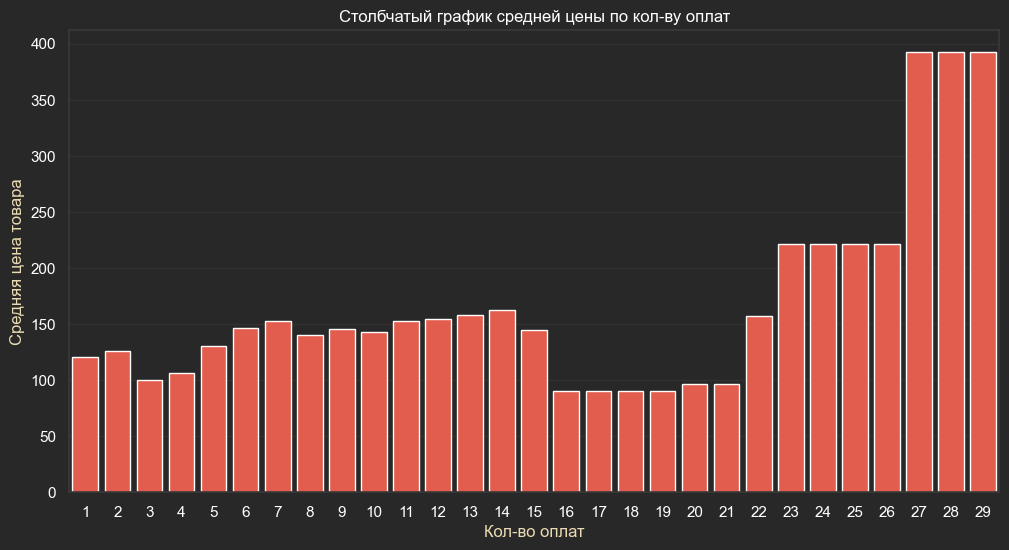

In [78]:
payment_sequential_price = df.groupby('payment_sequential').agg(
    price = ('price','mean'),
    mean_weight=('product_weight_g', 'mean')
)

plt.figure(figsize=(12,6))
sns.barplot(x = payment_sequential_price.index, y = payment_sequential_price['price'])
plt.title('Столбчатый график средней цены по кол-ву оплат')
plt.xlabel('Кол-во оплат')
plt.ylabel('Средняя цена товара')
plt.show()

Распределение цены товара по кол-ву оплат показало интересный результат - до 15 оплат на товар средняя цена держится в диапазоне 100-150 - это заказы, оплаченные кредитной картой в рассрочку на разумное количество платежей. После 15 оплат цена резко падает ниже 60. Что странноЮ, потому что логика подсказывает, чем дороже товар, тем больше платежей. Вероятнее всего, здесь дело в природе самих ваучеров -  при sequential >= 16 это уже не рассрочка за один дорогой товар, а оплата бонусами (кэшбэк, промокоды, купоны), которые дробятся на множество мелких транзакций для оплаты недорогих товаров.

In [79]:
df.groupby(df['product_photos_qty'].clip(upper=6)).agg(
    mean_price=('price', 'mean'),
    mean_review=('review_score', 'mean'),
    count=('price', 'count')
)

,mean_price,mean_review,count
product_photos_qty,,,
1.0,113.493076,3.999485,58275
2.0,111.457965,4.054188,22828
3.0,135.169674,4.079333,12832
4.0,146.100367,4.043578,8743
5.0,136.901016,4.145251,5549
6.0,137.788377,4.077957,7068


Присутствует слабая зависимость кол-ва фотографий на среднюю цену и оценку отзыва. У товаров с более чем 3 фотографиями в карточке цена и оценки немного выше, чем у товаров с одной или двумя фотографиями. 

In [80]:
pd.pivot_table(
    df,
    values='price',
    index='order_status',
    aggfunc=['mean', 'median', 'count']
).sort_values(('mean', 'price'), ascending=False)

,mean,median,count
,price,price,price
order_status,,,
unavailable,286.812857,99.000,7
canceled,182.742053,84.890,531
invoiced,172.226022,94.800,357
processing,168.198904,107.870,356
shipped,134.412933,79.965,1132
delivered,119.838134,74.900,112909
approved,69.866667,19.850,3


Цена товара монотонно растёт от delivered к unavailable/canceled - статусы сбоя заказа концентрируют более дорогие товары. Это может объясняться либо дефицитом дорогих позиций на складе продавца, либо повышенным риском срыва оплаты при крупных суммах.

#### Корреляция

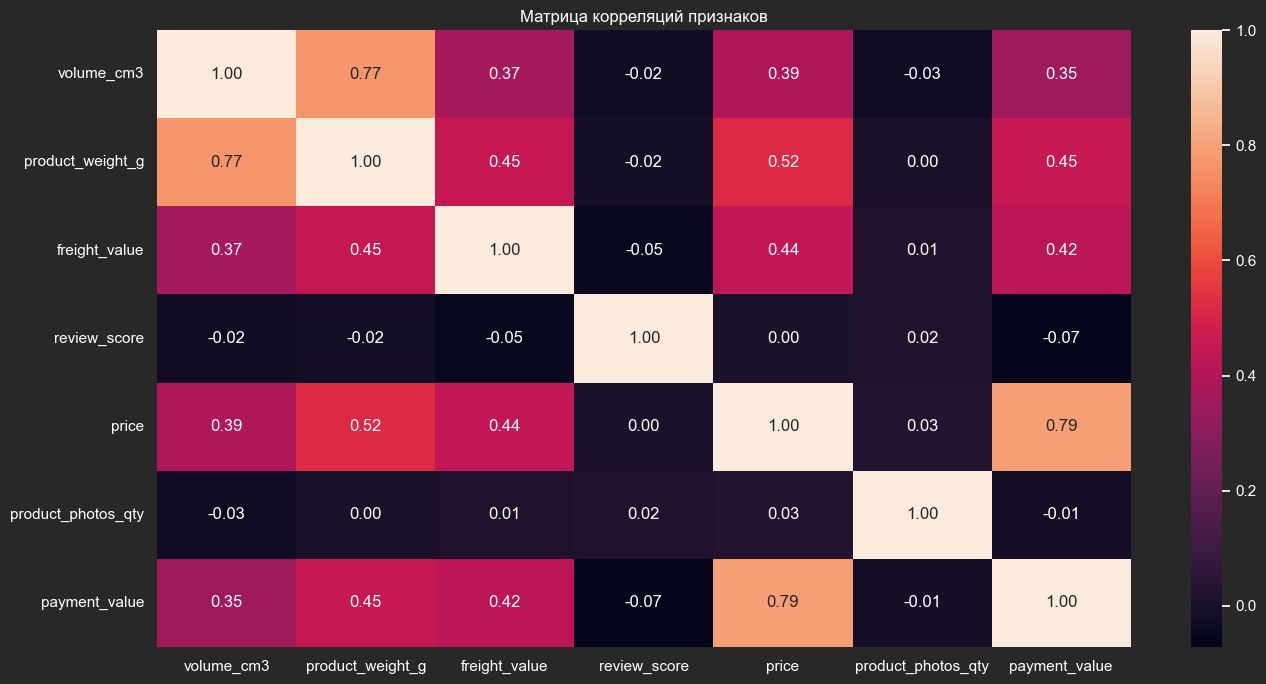

In [81]:
df['volume_cm3'] = df['product_length_cm'] * df['product_height_cm'] * df['product_width_cm']

plt.figure(figsize=(14,7))
sns.heatmap(
    df[['volume_cm3', 'product_weight_g', 'freight_value','review_score','price', 'product_photos_qty', 'payment_value']].corr(method='spearman'),
    annot=True,
    fmt='.2f',
    cbar=True
)
plt.title('Матрица корреляций признаков')
plt.tight_layout()
plt.show()

* price × payment_value = 0.79 - самая сильная связь. Логично: итоговая сумма оплаты определяется ценой товара плюс доставка, поэтому почти линейная зависимость. Один из признаков можно удалить

* product_weight_g × volume_cm3 = 0.77 - ожидаемо, объём и вес вместе несут схожую информацию.

* product_weight_g × price = 0.52 и freight_value × price = 0.43 - умеренные связи. Тяжёлые товары дороже и дороже стоят в доставке.

* review_score практически не коррелирует ни с чем числовым, максимум −0.07 с payment_value. Это подтверждает вывод из предыдущего анализа: удовлетворённость определяется не ценой и не весом.

* product_photos_qty - везде около нуля. Признак слабый в линейном смысле, но может работать в дереве через нелинейные разбиения.